# 05 · Evidence for combining the two record systems

Notebook 02 showed the old and new systems fill different fields. To analyse 2009-2026 as one series, each field the
dashboard needs must mean the same thing in both. This notebook gathers the evidence behind each option; **the
decisions themselves are Daniel's (stage 3, and stage 5 for categories)**.

| Field | Old system | New system | Question tested here |
|---|---|---|---|
| Spend category | GSIN code | UNSPSC code | How many GSIN codes would a map need? Can it be checked against UNSPSC? |
| Instrument type | missing | filled | Can it be inferred from the contract number? |
| Procurement method | filled | mostly filled | Are the labels used the same way? |
| Procurement category | filled | filled | Same distribution? |

Where the two systems are compared, only **FY2020-21 to FY2023-24** are used, the years when both were in use, so
differences are not just differences between eras (the mistake corrected in notebook 02).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from spendpipe import sources as S, eda
eda.apply_style()
pd.set_option("display.max_columns", 30, "display.width", 160, "display.max_colwidth", 60)

In [2]:
import re
import numpy as np
from spendpipe import config as C

rows = pd.concat([S.load("contracts_legacy"), S.load("contracts_current")], ignore_index=True)
rows["system"] = S.record_system(rows.contracting_entity)
first = S.first_rows(rows)
g = rows.groupby("contract_number")
code1 = lambda s: s.dropna().str.split("\n").str[0].str.lstrip("*").iloc[0] if s.notna().any() else None
contracts = pd.DataFrame({
    "system": first.system,
    "value": g.total_value.first().astype(float),
    "award": pd.to_datetime(g.award_date.min()),
    "gsin": g.gsin.agg(code1),           # first code on any row of the contract
    "unspsc": g.unspsc.agg(code1),
    "instrument": g.instrument_type.agg(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    "method": first.procurement_method,
    "category": first.procurement_category.str.split("\n").str[0],
})
contracts["fy"] = (contracts.award.dt.year - (contracts.award.dt.month < 4)).astype("Int64")
print(f"contracts: {len(contracts):,}")
print("multi-code cells:", {c: int(rows[c].str.contains("\n", na=False).sum()) for c in ["gsin", "unspsc"]})

contracts: 224,307
multi-code cells: {'gsin': 0, 'unspsc': 11683}


## 1. Spend category: how big would a GSIN map be?

GSIN codes have a structure. Goods codes are `N` + a 4-digit federal supply class (`N7030` = ADP software), whose
first two digits are a supply group (`N70` = computer equipment). Service codes start with a letter (`D` = IT
services, `R` = professional services). Construction codes start with two digits (`51`). So a code can be reduced
to a **prefix**, and a category map only needs one entry per prefix.

In [3]:
def gsin_prefix(code):
    if code is None or pd.isna(code):
        return None
    if re.match(r"N\d{2}", code):
        return "N" + code[1:3]
    if re.match(r"\d{2}", code):
        return code[:2]
    return code[0]

old = contracts[(contracts.system == "old") & (contracts.value > 0)].copy()
old["prefix"] = old.gsin.map(gsin_prefix)
by_prefix = old.groupby("prefix").value.agg(["sum", "size"]).sort_values("sum", ascending=False)
cum = by_prefix["sum"].cumsum() / by_prefix["sum"].sum()
print(f"old-system contracts with positive value: {len(old):,} | distinct GSIN codes: {old.gsin.nunique():,} | "
      f"distinct prefixes: {len(by_prefix)} | contracts with no GSIN: {old.gsin.isna().sum():,}")
for share in (0.8, 0.95, 0.99):
    print(f"  prefixes needed for {share:.0%} of value: {int((cum < share).sum()) + 1}")

old-system contracts with positive value: 186,092 | distinct GSIN codes: 5,184 | distinct prefixes: 99 | contracts with no GSIN: 0
  prefixes needed for 80% of value: 19
  prefixes needed for 95% of value: 34
  prefixes needed for 99% of value: 54


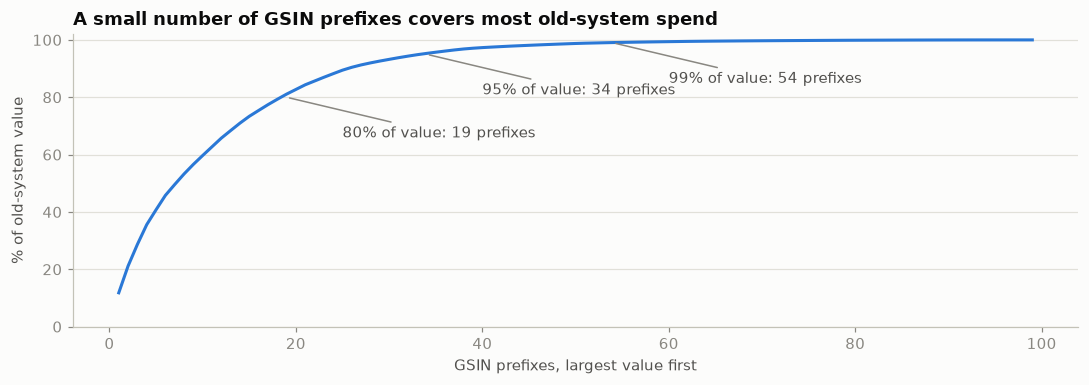

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(np.arange(1, len(cum) + 1), cum.values * 100, color=eda.SERIES[0])
for share in (80, 95, 99):
    k = int((cum * 100 < share).sum()) + 1
    ax.annotate(f"{share}% of value: {k} prefixes", (k, share), xytext=(k + 6, share - 14), color=eda.INK_2,
                arrowprops=dict(arrowstyle="-", color=eda.MUTED))
ax.set_xlabel("GSIN prefixes, largest value first")
ax.set_ylabel("% of old-system value")
ax.set_ylim(0, 102)
ax.set_title("A small number of GSIN prefixes covers most old-system spend")
fig.tight_layout()

In [5]:
desc = rows[rows.system == "old"].assign(prefix=lambda d: d.gsin.str.lstrip("*").map(gsin_prefix),
                                         d=lambda d: d.gsin_desc.str.lstrip("*"))
examples = desc.groupby("prefix").d.agg(lambda s: " | ".join(s.value_counts().head(2).index))
top = by_prefix.head(15).assign(value_B=lambda t: (t["sum"] / 1e9).round(1), examples=examples)
top[["value_B", "size", "examples"]].rename(columns={"size": "contracts"})

,value_B,contracts,examples
prefix,,,
C,33.5,7789,Architectual Services - Buildings | Engineering Services...
51,26.5,11269,"Construction of Other Buildings | Waterways, Harbours, D..."
M,21.4,145,Property and Facilities Management - Buildings | Operati...
D,19.5,4230,Informatics Professional Services | Information Products
N23,14.7,5686,"Trucks and Truck Tractors, Wheeled | Passenger Motor Veh..."
R,14.2,8123,"Human Resource Services, Business Consulting/Change Mana..."
J,10.8,6321,"Ships and Vessels (large) - Repair, Refits and Conversio..."
N70,10.4,20103,ADP Software | ADP Input-Output and Storage Devices
N58,9.5,4563,"Radio and Television Communications Equipment, Except Ai..."


## 2. Can a GSIN map be checked against UNSPSC?

4,918 contracts have rows from both systems (notebook 02): they started in the old system with a GSIN code and were
later amended in the new one with a UNSPSC code. The same purchase is coded both ways, which is what a check needs.
Below: for each GSIN prefix, how consistently its contracts fall into one UNSPSC segment, and which category the
**v1 UNSPSC map** would give them.

In [6]:
both = contracts.dropna(subset=["gsin", "unspsc"]).copy()
both["prefix"] = both.gsin.map(gsin_prefix)
both["segment"] = both.unspsc.str[:2]
both["v1_category"] = both.unspsc.map(lambda u: C.FAMILY_TO_CATEGORY.get(u[:4], C.SEGMENT_TO_CATEGORY.get(u[:2], C.UNCLASSIFIED)))
print(f"contracts coded both ways: {len(both):,} | covering {both.prefix.nunique()} of {len(by_prefix)} prefixes, "
      f"{old.prefix.isin(both.prefix).mean():.1%} of old-system contracts and "
      f"{old.loc[old.prefix.isin(both.prefix), 'value'].sum() / old.value.sum():.1%} of old-system value")
consistency = both.groupby("prefix").agg(
    contracts=("segment", "size"),
    top_segment_share=("segment", lambda s: s.value_counts(normalize=True).iloc[0]),
    top_v1_category=("v1_category", lambda s: s.value_counts().index[0]),
    top_category_share=("v1_category", lambda s: s.value_counts(normalize=True).iloc[0]))
consistency = consistency[consistency.contracts >= 20].sort_values("contracts", ascending=False)
w = consistency.contracts
print(f"prefixes with >= 20 dual-coded contracts: {len(consistency)} | contract-weighted share landing in the "
      f"prefix's most common v1 category: {(consistency.top_category_share * w).sum() / w.sum():.1%}")
consistency.head(15).style.format({"top_segment_share": "{:.0%}", "top_category_share": "{:.0%}"})

contracts coded both ways: 5,498 | covering 84 of 99 prefixes, 98.9% of old-system contracts and 99.1% of old-system value
prefixes with >= 20 dual-coded contracts: 30 | contract-weighted share landing in the prefix's most common v1 category: 76.4%


,contracts,top_segment_share,top_v1_category,top_category_share
prefix,,,,
D,1397,55%,Professional & Business Services,55%
R,1070,71%,Professional & Business Services,97%
51,328,87%,"Facilities, Construction & Environmental",89%
C,291,96%,"Engineering, Research & Technical Services",96%
K,202,57%,"Facilities, Construction & Environmental",79%
N66,187,66%,"Lab, Medical & Scientific",68%
T,187,53%,Professional & Business Services,84%
J,167,42%,"Facilities, Construction & Environmental",43%
N70,134,96%,"IT Hardware, Software & Telecom",96%


## 3. Instrument type: can it be inferred for old-system contracts?

Instrument type matters because a standing offer or supply arrangement records a ceiling, not spend. If the contract
number's format revealed the instrument, old-system contracts could be labelled. Test it on new-system contracts,
where the answer is known: replace digits with `9` and letters with `A`, and cross-tabulate.

In [7]:
new = contracts[contracts.system == "new"].copy()
new["shape"] = (new.index.str.replace(r"\d", "9", regex=True).str.replace(r"[A-Z]", "A", regex=True)
                .str.replace(r"/999/A+$", "/999/X", regex=True))
xt = pd.crosstab(new["shape"], new.instrument)
xt.loc[xt.sum(axis=1).sort_values(ascending=False).index].head(6)

instrument,Contract,Contract against SA,Standing Offer,Supply Arrangement,Task Authorization Based Contract
shape,,,,,
AA9999999,9033,1476,2803,2523,522
AA999-999999/999/X,62,0,177,268,0
A99AA-999999/999/X,0,2,18,464,0
A9999-999999/999/X,53,7,22,38,4
A99AA-99AAAA/999/X,4,0,2,72,0
99999-999999/999/X,19,0,13,0,7


## 4. Procurement method and category: are the labels used the same way?

Only contracts awarded FY2020-21 to FY2023-24, by system of the first row (% of contracts).

In [8]:
overlap = contracts[contracts.fy.between(2020, 2023)]
print("contracts in the overlap years:", overlap.system.value_counts().to_dict())
method = (pd.crosstab(overlap.method.fillna("(blank)"), overlap.system, normalize="columns") * 100).round(1)
method["grouped as"] = method.index.map(lambda m: "competitive" if m.startswith("Competitive")
                                        else "non-competitive" if m.startswith("Non") else
                                        "ACAN" if m.startswith("Advance") else "not reported")
method

contracts in the overlap years: {'old': 14814, 'new': 7836}


system,new,old,grouped as
method,,,
(blank),15.5,0.0,not reported
Advance contract award notice,1.5,1.6,ACAN
Competitive - Open bidding,43.0,56.7,competitive
Competitive - Selective tendering,8.8,0.0,competitive
Competitive - Traditional,3.2,13.7,competitive
Non-competitive,27.9,28.1,non-competitive


In [9]:
grouped = overlap.assign(group=overlap.method.fillna("(blank)").map(lambda m: "competitive" if m.startswith("Competitive")
                         else "non-competitive" if m.startswith("Non") else "ACAN" if m.startswith("Advance")
                         else "not reported"))
print("grouped, % of contracts:")
print((pd.crosstab(grouped.group, grouped.system, normalize="columns") * 100).round(1))
blank_new = overlap[(overlap.system == "new") & overlap.method.isna()]
print("\nnew-system contracts with blank method, by instrument type:", blank_new.instrument.value_counts().to_dict())

grouped, % of contracts:
system            new   old
group                      
ACAN              1.5   1.6
competitive      55.0  70.3
non-competitive  27.9  28.1
not reported     15.5   0.0

new-system contracts with blank method, by instrument type: {'Supply Arrangement': 720, 'Standing Offer': 297, 'Contract': 136, 'Contract against SA': 44, 'Task Authorization Based Contract': 18}


In [10]:
(pd.crosstab(overlap.category, overlap.system, normalize="columns") * 100).round(1)

system,new,old
category,,
*CNST,0.1,7.3
*GD,50.8,44.3
*SRV,49.2,42.6
*SRVTGD,0.0,5.8


## Findings

1. **A GSIN map is a manageable size.** Old-system contracts use 5,184 GSIN codes but only 99 prefixes; 19 prefixes
   cover 80% of value, 34 cover 95%, 54 cover 99%. Every old-system contract has a GSIN code.
2. **It can be checked against UNSPSC.** 5,498 contracts carry both codes, and their prefixes cover 98.9% of
   old-system contracts. Across the 30 prefixes with at least 20 such contracts, 76.4% of contracts land in the
   prefix's most common v1 category. Some prefixes are clean (R professional services 97%, C architecture and
   engineering 96%, N70 computer equipment 96%); others are mixed (J ship repair 43%, N58 communications equipment
   41%, B special studies 37%) and would need code-level rules. The 76.4% is a first estimate of how often a
   prefix-level map would agree with UNSPSC. It could become the validation metric for categorisation (stage 5).
3. **Instrument type cannot be inferred** from the contract number: the `CW1234567` format is used for all five
   instrument types. For old-system contracts it stays unknown.
4. **Procurement method can be grouped.** In the overlap years, non-competitive is 27.9% (new) vs 28.1% (old) and
   ACAN 1.5% vs 1.6%. The detailed competitive labels are used differently ("Traditional" 13.7% old vs 3.2% new;
   "Selective tendering" only in new), but all are competitive. The new system leaves the method blank on 15.5% of
   contracts, mostly supply arrangements (720) and standing offers (297).
5. **Procurement category is not comparable across systems.** In the same years, the new system almost never uses
   Construction (0.1% vs 7.3%) or Services-related-to-goods (0.0% vs 5.8%). It cannot serve as a common category
   fallback.